In [74]:
# 1. Import Library & Load Dataset
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dataset_path = 'dataset/index_data.csv' if os.path.exists('dataset/index_data.csv') else '../dataset/index_data.csv'
df = pd.read_csv(dataset_path)
print(f"Data berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Data berhasil dimuat: 1765 baris, 9 kolom


,Nama Suami,Nama Istri,Usia Suami,Usia Istri,Pendidikan Suami,Pendidikan Istri,Pekerjaan Suami,Pekerjaan Istri,Tahun
0,DEDE IRSAN,PUJI WIDIASTUTI,27,24,SLTP/SEDERAJAT,SLTA/SEDERAJAT,PELAJAR / MAHASISWA,PELAJAR / MAHASISWA,2021
1,SUPRIATNA MOCHAMMAD SAMAWI,SUSANTI,24,20,SLTA/SEDERAJAT,SLTP/SEDERAJAT,PELAJAR / MAHASISWA,PELAJAR / MAHASISWA,2021
2,SUHENDI,ELA LAELAWATI,40,39,SLTP/SEDERAJAT,SLTP/SEDERAJAT,WIRASWASTA,MENGURUS RUMAH TANGGA,2021
3,ARI HANA SUPARMAN,ANAH SUMIANGSIH,31,26,SLTA/SEDERAJAT,TAMAT SD/SEDERAJATNYA,BELUM / TIDAK BEKERJA,PELAJAR / MAHASISWA,2021
4,UJANG ALI ROHMAN,SITI HILMAH SHOFIYAH,24,21,SLTA/SEDERAJAT,TAMAT SD/SEDERAJATNYA,BELUM / TIDAK BEKERJA,BELUM / TIDAK BEKERJA,2021


In [75]:
# 2. Preprocessing, Feature Engineering & Ground Truth Labeling
# Koreksi anomali usia 0
df.loc[df['Usia Istri'] == 0, 'Usia Istri'] = 20
df['Pendidikan Suami'] = df['Pendidikan Suami'].fillna('TIDAK DIKETAHUI')
df['Pendidikan Istri'] = df['Pendidikan Istri'].fillna('TIDAK DIKETAHUI')

# A. Pengelompokan Kemapanan Ekonomi Suami (Pencari Nafkah Utama)
def kategori_pekerjaan_suami(p):
    p = str(p).upper().strip()
    if any(k in p for k in ['PNS', 'POLISI', 'TNI', 'TENTARA', 'BUMD', 'BUMN', 'DOKTER', 'DOSEN', 'GURU', 'PERAWAT', 'PERANGKAT DESA', 'PPPK', 'KARYAWAN SWASTA']):
        return 'Tetap/Mapan'
    elif any(k in p for k in ['WIRASWASTA', 'PEDAGANG', 'PERDAGANGAN', 'PETANI', 'PETERNAK', 'PETAMBAK', 'TAMBANG']):
        return 'Mandiri/Wiraswasta'
    elif any(k in p for k in ['BURUH', 'SOPIR', 'HONORER', 'SENI']):
        return 'Tidak Tetap/Buruh'
    else:
        return 'Tidak Bekerja'

# B. Pengelompokan Peran Ekonomi Istri (Penopang Sekunder / Mitra Domestik)
def kategori_pekerjaan_istri(p):
    p = str(p).upper().strip()
    if 'MENGURUS RUMAH TANGGA' in p:
        return 'Mengurus Rumah Tangga'
    elif any(k in p for k in ['PNS', 'POLISI', 'TNI', 'BUMD', 'BUMN', 'DOKTER', 'DOSEN', 'PERAWAT', 'BIDAN', 'KARYAWAN SWASTA', 'WIRASWASTA']) or p in ['GURU', 'GURU HONORER']:
        return 'Bekerja/Berpenghasilan'
    elif 'BURUH' in p:
        return 'Pekerja Tidak Tetap'
    else:
        return 'Belum Bekerja/Pelajar'

# C. Pengelompokan Usia Berdasarkan Kategori Hukum & Kematangan (Binning Usia)
def kategori_usia(u):
    if u < 19:
        return '< 19 (Di Bawah Umur)'
    elif u <= 24:
        return '19-24 (Muda)'
    elif u <= 30:
        return '25-30 (Matang)'
    else:
        return '> 30 (Dewasa)'

df['Kategori_Pekerjaan_Suami'] = df['Pekerjaan Suami'].apply(kategori_pekerjaan_suami)
df['Kategori_Pekerjaan_Istri'] = df['Pekerjaan Istri'].apply(kategori_pekerjaan_istri)
df['Kategori_Usia_Suami'] = df['Usia Suami'].apply(kategori_usia)
df['Kategori_Usia_Istri'] = df['Usia Istri'].apply(kategori_usia)

# D. Penentuan Label Target Kelayakan (UU Perkawinan No. 16/2019 + Sinergi Ekonomi Suami & Istri):
# Syarat Hukum: Suami >= 19 th DAN Istri >= 19 th
syarat_usia_sah = (df['Usia Suami'] >= 19) & (df['Usia Istri'] >= 19)

# Syarat Ekonomi Keluarga (Suami nafkah utama, Istri sekunder):
# 1. Suami Tetap/Mapan atau Mandiri/Wiraswasta -> Layak (istri IRT maupun bekerja tetap ideal)
suami_mapan = df['Kategori_Pekerjaan_Suami'].isin(['Tetap/Mapan', 'Mandiri/Wiraswasta'])
# 2. Suami Buruh/Tidak Tetap, TAPI Istri Bekerja/Berpenghasilan -> Layak (Dual-income menopang ekonomi)
suami_buruh_istri_bekerja = (df['Kategori_Pekerjaan_Suami'] == 'Tidak Tetap/Buruh') & (df['Kategori_Pekerjaan_Istri'] == 'Bekerja/Berpenghasilan')

syarat_ekonomi_layak = suami_mapan | suami_buruh_istri_bekerja
df['Status_Kelayakan'] = np.where(syarat_usia_sah & syarat_ekonomi_layak, 'Layak', 'Tidak Layak')

print('Distribusi Label Status Kelayakan:')
print(df['Status_Kelayakan'].value_counts())
print(f"\nPersentase:\n{df['Status_Kelayakan'].value_counts(normalize=True) * 100}")

Distribusi Label Status Kelayakan:
Status_Kelayakan
Tidak Layak    1387
Layak           378
Name: count, dtype: int64

Persentase:
Status_Kelayakan
Tidak Layak    78.583569
Layak          21.416431
Name: proportion, dtype: float64


In [76]:
# 3. One-Hot Encoding Fitur & Split Data Latih/Uji
feature_cols = ['Kategori_Usia_Suami', 'Kategori_Usia_Istri', 'Kategori_Pekerjaan_Suami', 'Kategori_Pekerjaan_Istri', 'Pendidikan Suami', 'Pendidikan Istri']

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X = encoder.fit_transform(df[feature_cols])
y = df['Status_Kelayakan']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Total fitur setelah One-Hot Encoding: {X.shape[1]} kolom biner')
print(f'Jumlah Data Latih: {X_train.shape[0]} | Data Uji: {X_test.shape[0]}')

Total fitur setelah One-Hot Encoding: 45 kolom biner
Jumlah Data Latih: 1412 | Data Uji: 353


In [77]:
# 4. Training Model Multinomial Naive Bayes
nb_model = MultinomialNB(alpha=1.0) # alpha=1.0 adalah Laplace Smoothing
nb_model.fit(X_train, y_train)
print('Model Multinomial Naive Bayes berhasil dilatih!')

Model Multinomial Naive Bayes berhasil dilatih!


In [78]:
# 5. Evaluasi Model
y_pred = nb_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=['Layak', 'Tidak Layak'])

print('================ HASIL EVALUASI MODEL ================')
print(f'Akurasi: {acc * 100:.2f}%\n')
print('Confusion Matrix:')
print(cm)
print('\nClassification Report:')
print(classification_report(y_test, y_pred))

================ HASIL EVALUASI MODEL ================
Akurasi: 98.30%

Confusion Matrix:
[[ 75   1]
 [  5 272]]

Classification Report:
              precision    recall  f1-score   support

       Layak       0.94      0.99      0.96        76
 Tidak Layak       1.00      0.98      0.99       277

    accuracy                           0.98       353
   macro avg       0.97      0.98      0.98       353
weighted avg       0.98      0.98      0.98       353



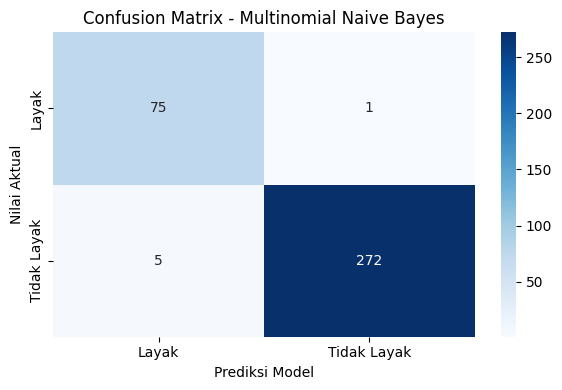

In [79]:
# 6. Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Layak', 'Tidak Layak'],
            yticklabels=['Layak', 'Tidak Layak'])
plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Prediksi Model')
plt.ylabel('Nilai Aktual')
plt.tight_layout()
plt.show()

In [80]:
# 7. 10-Fold Cross Validation
cv_scores = cross_val_score(nb_model, X, y, cv=10, scoring='accuracy')

print('Skor Akurasi 10-Fold CV:')
for i, score in enumerate(cv_scores, 1):
    print(f'  Fold {i:2d}: {score * 100:.2f}%')

print(f'\nRata-rata Akurasi (Mean CV): {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)')

Skor Akurasi 10-Fold CV:
  Fold  1: 98.87%
  Fold  2: 96.05%
  Fold  3: 96.61%
  Fold  4: 96.05%
  Fold  5: 98.31%
  Fold  6: 98.86%
  Fold  7: 98.30%
  Fold  8: 97.16%
  Fold  9: 97.73%
  Fold 10: 95.45%

Rata-rata Akurasi (Mean CV): 97.34% (+/- 1.19%)


In [81]:
# 8. Simulasi Prediksi Data Pasangan Baru (Fungsi Prediksi Praktis)
def prediksi_kelayakan(usia_suami, usia_istri, pekerjaan_suami, pekerjaan_istri, pendidikan_suami='SLTA/SEDERAJAT', pendidikan_istri='SLTA/SEDERAJAT'):
    input_raw = pd.DataFrame([{
        'Kategori_Usia_Suami': kategori_usia(usia_suami),
        'Kategori_Usia_Istri': kategori_usia(usia_istri),
        'Kategori_Pekerjaan_Suami': kategori_pekerjaan_suami(pekerjaan_suami),
        'Kategori_Pekerjaan_Istri': kategori_pekerjaan_istri(pekerjaan_istri),
        'Pendidikan Suami': pendidikan_suami,
        'Pendidikan Istri': pendidikan_istri
    }])
    input_encoded = encoder.transform(input_raw[feature_cols])
    hasil = nb_model.predict(input_encoded)[0]
    prob = {str(k): round(float(v) * 100, 2) for k, v in zip(nb_model.classes_, nb_model.predict_proba(input_encoded)[0])}
    return hasil, prob

# Uji Coba Kasus 1: Usia di bawah 19 tahun & Suami Buruh Lepas, Istri IRT (Tidak Memenuhi Syarat Usia & Ekonomi)
hasil_1, prob_1 = prediksi_kelayakan(17, 15, 'BURUH HARIAN LEPAS', 'MENGURUS RUMAH TANGGA', 'SLTA/SEDERAJAT', 'SLTP/SEDERAJAT')
print('--- UJI KASUS 1 (Usia 17 & 15, Suami Buruh Lepas, Istri IRT) ---')
print(f'Hasil Prediksi : {hasil_1}')
print(f'Probabilitas   : {prob_1}\n')

# Uji Coba Kasus 2: Usia Matang & Suami Karyawan Swasta (Mapan), Istri IRT (Ideal)
hasil_2, prob_2 = prediksi_kelayakan(27, 24, 'KARYAWAN SWASTA', 'MENGURUS RUMAH TANGGA', 'SLTA/SEDERAJAT', 'SLTA/SEDERAJAT')
print('--- UJI KASUS 2 (Usia 27 & 24, Suami Karyawan Swasta, Istri IRT) ---')
print(f'Hasil Prediksi : {hasil_2}')
print(f'Probabilitas   : {prob_2}\n')

# Uji Coba Kasus 3: Usia Matang & Suami Buruh Lepas, Istri IRT (Usia Cukup, Namun Ekonomi Belum Mapan)
hasil_3, prob_3 = prediksi_kelayakan(25, 22, 'BURUH HARIAN LEPAS', 'MENGURUS RUMAH TANGGA', 'SLTA/SEDERAJAT', 'SLTA/SEDERAJAT')
print('--- UJI KASUS 3 (Usia 25 & 22, Suami Buruh Lepas, Istri IRT) ---')
print(f'Hasil Prediksi : {hasil_3}')
print(f'Probabilitas   : {prob_3}\n')

# Uji Coba Kasus 4: Usia Matang & Suami PNS, Istri PNS (Dual Career / Sangat Mapan)
hasil_4, prob_4 = prediksi_kelayakan(28, 26, 'PEGAWAI NEGERI SIPIL (PNS)', 'PEGAWAI NEGERI SIPIL (PNS)', 'DIPLOMA IV/STRATA I', 'DIPLOMA IV/STRATA I')
print('--- UJI KASUS 4 (Usia 28 & 26, Suami PNS, Istri PNS) ---')
print(f'Hasil Prediksi : {hasil_4}')
print(f'Probabilitas   : {prob_4}')

--- UJI KASUS 1 (Usia 17 & 15, Suami Buruh Lepas, Istri IRT) ---
Hasil Prediksi : Tidak Layak
Probabilitas   : {'Layak': 0.96, 'Tidak Layak': 99.04}

--- UJI KASUS 2 (Usia 27 & 24, Suami Karyawan Swasta, Istri IRT) ---
Hasil Prediksi : Layak
Probabilitas   : {'Layak': 94.53, 'Tidak Layak': 5.47}

--- UJI KASUS 3 (Usia 25 & 22, Suami Buruh Lepas, Istri IRT) ---
Hasil Prediksi : Tidak Layak
Probabilitas   : {'Layak': 5.64, 'Tidak Layak': 94.36}

--- UJI KASUS 4 (Usia 28 & 26, Suami PNS, Istri PNS) ---
Hasil Prediksi : Layak
Probabilitas   : {'Layak': 99.93, 'Tidak Layak': 0.07}


In [82]:
# 9. Menyimpan Model dan Preprocessor (.pkl)
models_dir = 'models'
os.makedirs(models_dir, exist_ok=True)

joblib.dump(nb_model, os.path.join(models_dir, 'naive_bayes.pkl'))
joblib.dump(encoder, os.path.join(models_dir, 'preprocessor.pkl'))
joblib.dump(feature_cols, os.path.join(models_dir, 'features.pkl'))

print('Berhasil menyimpan model & preprocessor ke folder /models:')
print(f" - {os.path.join(models_dir, 'naive_bayes.pkl')}")
print(f" - {os.path.join(models_dir, 'preprocessor.pkl')}")
print(f" - {os.path.join(models_dir, 'features.pkl')}")

Berhasil menyimpan model & preprocessor ke folder /models:
 - models\naive_bayes.pkl
 - models\preprocessor.pkl
 - models\features.pkl


In [83]:
# 10. Pengujian Memuat (Load) Model & Preprocessor dari file .pkl
loaded_model = joblib.load(os.path.join(models_dir, 'naive_bayes.pkl'))
loaded_encoder = joblib.load(os.path.join(models_dir, 'preprocessor.pkl'))
loaded_features = joblib.load(os.path.join(models_dir, 'features.pkl'))

# Verifikasi uji prediksi menggunakan objek yang di-load dari file .pkl
test_input = pd.DataFrame([{
    'Kategori_Usia_Suami': '< 19 (Di Bawah Umur)',
    'Kategori_Usia_Istri': '< 19 (Di Bawah Umur)',
    'Kategori_Pekerjaan_Suami': 'Tidak Tetap/Buruh',
    'Kategori_Pekerjaan_Istri': 'Mengurus Rumah Tangga',
    'Pendidikan Suami': 'SLTA/SEDERAJAT',
    'Pendidikan Istri': 'SLTP/SEDERAJAT'
}])

test_X = loaded_encoder.transform(test_input[loaded_features])
pred_pkl = loaded_model.predict(test_X)[0]
print(f'Verifikasi Hasil Prediksi dari .pkl (Kasus Usia < 19, Suami Buruh & Istri IRT): {pred_pkl}')

Verifikasi Hasil Prediksi dari .pkl (Kasus Usia < 19, Suami Buruh & Istri IRT): Tidak Layak
